# Taller 2 - Ciencia de Datos Aplicada
## Punto 1: Entendimiento y preparación de los datos

El análisis diferencia datos crudos de datos limpios. La preparación se hace de modo que el entrenamiento posterior pueda validarse sin fuga de información.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

RANDOM_STATE = 42
df_raw = pd.read_csv(Path("churn.csv"))
print("Dimensiones originales:", df_raw.shape)
display(df_raw.head())

Dimensiones originales: (10045, 11)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


### 1.0. Diccionario de datos y estructura

| Variable | Tipo conceptual | Interpretación |
|---|---|---|
| `credit_score` | Numérica | Puntaje de crédito del cliente |
| `country` | Categórica nominal | País: Francia, Alemania o España (con variaciones de escritura) |
| `gender` | Categórica nominal | Género consignado en el dataset |
| `age` | Numérica | Edad en años |
| `tenure` | Numérica discreta | Antigüedad de la relación con el banco (años) |
| `balance` | Numérica | Saldo de la cuenta |
| `products_number` | Discreta | Cantidad de productos bancarios |
| `credit_card` | Binaria | Indica tenencia de tarjeta de crédito |
| `active_member` | Binaria | Indica si el cliente es activo |
| `estimated_salary` | Numérica | Salario estimado |
| `churn` | Binaria / objetivo | 1: abandono; 0: no abandono |

No hay una columna de identificador en el CSV suministrado. Por eso, los duplicados exactos se revisan sobre todos los atributos disponibles. No es posible verificar la unicidad de personas distintas mediante un ID.

In [2]:
resumen_columnas = pd.DataFrame({
    "dtype_python": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "porcentaje_nulos": (df_raw.isna().mean() * 100).round(2),
    "valores_distintos": df_raw.nunique(dropna=True),
})
display(resumen_columnas)
print("Duplicados exactos:", int(df_raw.duplicated().sum()))
print("Filas con algún nulo:", int(df_raw.isna().any(axis=1).sum()))
print("Total de celdas nulas:", int(df_raw.isna().sum().sum()))
display(df_raw.describe().T.round(2))

,dtype_python,nulos,porcentaje_nulos,valores_distintos
credit_score,float64,250,2.49,461
country,object,0,0.00,9
gender,object,0,0.00,4
age,float64,300,2.99,76
tenure,int64,0,0.00,14
balance,float64,200,1.99,6240
products_number,int64,0,0.00,4
credit_card,int64,0,0.00,2
active_member,int64,0,0.00,2
estimated_salary,float64,350,3.48,9649


Duplicados exactos: 45
Filas con algún nulo: 1100
Total de celdas nulas: 1100


,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.69,97.09,95.0,584.00,652.00,718.00,1200.00
age,9745.0,38.94,10.73,-1.0,32.00,37.00,44.00,210.00
tenure,10045.0,5.02,2.90,-2.0,3.00,5.00,8.00,25.00
balance,9845.0,76317.50,62422.43,0.0,0.00,97042.60,127559.97,250898.09
products_number,10045.0,1.53,0.58,1.0,1.00,1.00,2.00,4.00
credit_card,10045.0,0.70,0.46,0.0,0.00,1.00,1.00,1.00
active_member,10045.0,0.51,0.50,0.0,0.00,1.00,1.00,1.00
estimated_salary,9695.0,100069.01,57510.69,-5000.0,51013.66,100130.95,149382.88,199992.48
churn,10045.0,0.20,0.40,0.0,0.00,0.00,0.00,1.00


### 1.1. Calidad de los datos

Se revisan las cuatro dimensiones vistas en clase: unicidad, completitud, consistencia y validez.

#### 1.1.1 Unicidad

In [3]:
n_dup = df_raw.duplicated().sum()
print(f'Filas duplicadas exactas: {n_dup} ({n_dup / len(df_raw):.2%})')
df_raw[df_raw.duplicated(keep=False)].sort_values(list(df_raw.columns)).head(6)

Filas duplicadas exactas: 45 (0.45%)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
5672,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
2390,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
7450,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
2784,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0
6920,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0


#### 1.1.2 Completitud

In [4]:
nulos = pd.DataFrame({'nulos': df_raw.isna().sum(), '% del total': df_raw.isna().mean() * 100})
display(nulos[nulos['nulos'] > 0])
nulos_por_fila = df_raw.isna().sum(axis=1)
print(f'Filas con al menos un nulo: {(nulos_por_fila > 0).sum():,} ({(nulos_por_fila > 0).mean():.2%})')
print('Filas según cantidad de nulos:', nulos_por_fila.value_counts().sort_index().to_dict())

,nulos,% del total
credit_score,250,2.488800
age,300,2.986560
balance,200,1.991040
estimated_salary,350,3.484321


Filas con al menos un nulo: 1,100 (10.95%)
Filas según cantidad de nulos: {0: 8945, 1: 1100}


Cuatro columnas tienen nulos, todas por debajo del 5 %: `credit_score`, `age`, `balance` y `estimated_salary`.

#### 1.1.3 Consistencia

In [5]:
for col in ['country', 'gender']:
    print(f'--- {col}')
    print(df_raw[col].map(repr).value_counts().to_string(), '\n')

--- country
country
'France'      5003
'Germany'     2502
'Spain'       2475
'FRANCE'        22
'france '       17
'GERMANY'        9
'SPAIN'          9
'germany '       6
'spain '         2 

--- gender
gender
'Male'      5464
'Female'    4551
'M'           16
'F'           14 



- `country`: además de `France`, `Germany` y `Spain` aparecen variantes en mayúsculas (`FRANCE`) y en minúsculas con un espacio al final (`'france '`). Son 65 registros.
- `gender`: además de `Female` y `Male` aparecen las abreviaturas `F` y `M` (30 registros).

Si no se corrigen, el *one-hot encoding* crearía columnas distintas para el mismo país o género.

#### 1.1.4 Validez

In [6]:
rangos = {'credit_score': (300, 850), 'age': (18, 100), 'tenure': (0, 10),
          'balance': (0, None), 'products_number': (1, 4), 'estimated_salary': (0, None)}

def fuera_de_rango(df):
    filas = []
    for col, (lo, hi) in rangos.items():
        s = df[col]
        bajo = s < lo
        alto = s > hi if hi is not None else pd.Series(False, index=s.index)
        filas.append({'variable': col, 'rango válido': f'{lo} a {hi if hi is not None else "∞"}',
                      'bajo el mínimo': int(bajo.sum()), 'sobre el máximo': int(alto.sum()),
                      'valores inválidos': sorted(s[bajo | alto].tolist())})
    return pd.DataFrame(filas).set_index('variable')

for col in ['credit_card', 'active_member', 'churn']:
    assert set(df_raw[col].unique()) <= {0, 1}, col
fuera_de_rango(df_raw)

,rango válido,bajo el mínimo,sobre el máximo,valores inválidos
variable,,,,
credit_score,300 a 850,2,2,"[95.0, 120.0, 999.0, 1200.0]"
age,18 a 100,3,3,"[-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]"
tenure,0 a 10,1,2,"[-2, 15, 25]"
balance,0 a ∞,0,0,[]
products_number,1 a 4,0,0,[]
estimated_salary,0 a ∞,3,0,"[-5000.0, -120.5, -1.0]"


Hay 16 valores fuera de rango en cuatro variables. Las binarias, `balance` y `products_number` están dentro de su rango. Los valores inválidos no son extremos sino imposibles: edades de 0, −1, 5, 130, 150 y 210 años; un `credit_score` de 999 o de 95; antigüedades de −2 y 25 años; salarios negativos.

#### 1.1.5 Resumen de calidad

In [7]:
resumen_calidad = pd.DataFrame([
    ('Unicidad',     'Filas duplicadas exactas',                     n_dup),
    ('Completitud',  'Celdas nulas (4 columnas)',                    int(df_raw.isna().sum().sum())),
    ('Consistencia', 'Registros con country mal escrito',            int((~df_raw['country'].isin(['France', 'Germany', 'Spain'])).sum())),
    ('Consistencia', 'Registros con gender abreviado',               int((~df_raw['gender'].isin(['Female', 'Male'])).sum())),
    ('Validez',      'Valores fuera del rango del diccionario',      int(fuera_de_rango(df_raw)[['bajo el mínimo', 'sobre el máximo']].sum().sum())),
], columns=['dimensión', 'problema', 'casos']).set_index('dimensión')
resumen_calidad['% de registros'] = resumen_calidad['casos'] / len(df_raw) * 100
resumen_calidad

,problema,casos,% de registros
dimensión,,,
Unicidad,Filas duplicadas exactas,45,0.447984
Completitud,Celdas nulas (4 columnas),1100,10.950722
Consistencia,Registros con country mal escrito,65,0.647088
Consistencia,Registros con gender abreviado,30,0.298656
Validez,Valores fuera del rango del diccionario,16,0.159283


### 1.2. Auditoría de calidad

Hallazgos sobre el CSV original: existen 45 filas idénticas; hay valores faltantes en `credit_score`, `age`, `balance` y `estimated_salary`. `country` aparece con diferentes mayúsculas y `gender` mezcla nombres completos con abreviaturas. También hay valores numéricos improbables.

**Procedimiento de limpieza a ejecutar:**

1. Estandarizar países y géneros (por ejemplo, `FRANCE` -> `France`, `F` -> `Female`).
2. Eliminar filas duplicadas exactas. No se eliminarán clientes solo porque compartan una o dos características.
3. Convertir a faltante (`NaN`) los valores numéricos imposibles o fuera de los rangos adoptados: edad fuera de 18–100, antigüedad fuera de 0–10, puntaje crediticio fuera de 300–850 y salario negativo. Los rangos para antigüedad y puntaje son supuestos sobre este dataset, no reglas universales de todas las entidades financieras.
4. No eliminar las filas que contienen valores faltantes: se imputarán más adelante, aprendiendo las estadísticas exclusivamente del conjunto de entrenamiento.

In [8]:
# Crear una copia. El archivo original se conserva intacto.
df = df_raw.copy()
df["country"] = df["country"].astype("string").str.strip().str.title()
df["gender"] = df["gender"].astype("string").str.strip().replace({"F": "Female", "M": "Male"})

filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
duplicados_eliminados = filas_antes - len(df)

# Los valores fuera del dominio adoptado pasan a NaN: la imputación irá en el pipeline.
limites = {"credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10)}
corregidos = {}
for col, (minimo, maximo) in limites.items():
    mask = df[col].notna() & ~df[col].between(minimo, maximo)
    corregidos[col] = int(mask.sum())
    df.loc[mask, col] = np.nan
mask_salario = df["estimated_salary"].lt(0)
corregidos["estimated_salary"] = int(mask_salario.sum())
df.loc[mask_salario, "estimated_salary"] = np.nan

print(f"Registros antes: {filas_antes:,} | duplicados eliminados: {duplicados_eliminados} | después: {len(df):,}")
print("Anomalías numéricas convertidas a NaN:", corregidos)
print("Nulos después de la limpieza:")
display(pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (100*df.isna().mean()).round(2)}))

Registros antes: 10,045 | duplicados eliminados: 45 | después: 10,000
Anomalías numéricas convertidas a NaN: {'credit_score': 4, 'age': 6, 'tenure': 3, 'estimated_salary': 3}
Nulos después de la limpieza:


,nulos,porcentaje
credit_score,254,2.54
country,0,0.00
gender,0,0.00
age,306,3.06
tenure,3,0.03
balance,200,2.00
products_number,0,0.00
credit_card,0,0.00
active_member,0,0.00
estimated_salary,353,3.53


### 1.3. Distribución de la variable objetivo

La tasa de abandono se calcula como la proporción de registros en que churn = 1. Conviene reportar la proporción antes y después de la depuración para verificar que la limpieza no ha alterado sustancialmente la composición de las clases.

,Conjunto,Clientes,Abandonan,Tasa de abandono (%)
0,Original,10045,2045,20.36
1,Depurado,10000,2037,20.37


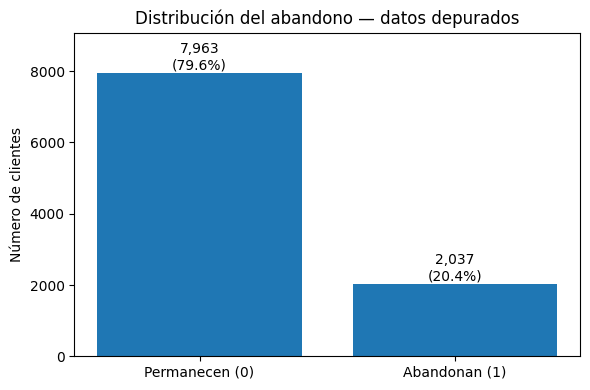

In [9]:
comparacion = pd.DataFrame({
    "Conjunto": ["Original", "Depurado"],
    "Clientes": [len(df_raw), len(df)],
    "Abandonan": [int(df_raw.churn.sum()), int(df.churn.sum())],
    "Tasa de abandono (%)": [round(100*df_raw.churn.mean(), 2), round(100*df.churn.mean(), 2)],
})
display(comparacion)

conteos = df["churn"].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Permanecen (0)", "Abandonan (1)"], conteos.values)
for barra, valor in zip(bars, conteos.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 90, f"{valor:,}\n({100*valor/len(df):.1f}%)", ha="center")
ax.set_ylim(0, max(conteos.values)*1.14)
ax.set_ylabel("Número de clientes")
ax.set_title("Distribución del abandono — datos depurados")
plt.tight_layout(); plt.show()

### 1.4. Distribuciones numéricas

Los histogramas permiten revisar la dispersión de las variables numéricas y posibles acumulaciones. La comparación entre churn = 0 y churn = 1 puede sugerir asociaciones útiles, pero no puede demostrar causalidad.

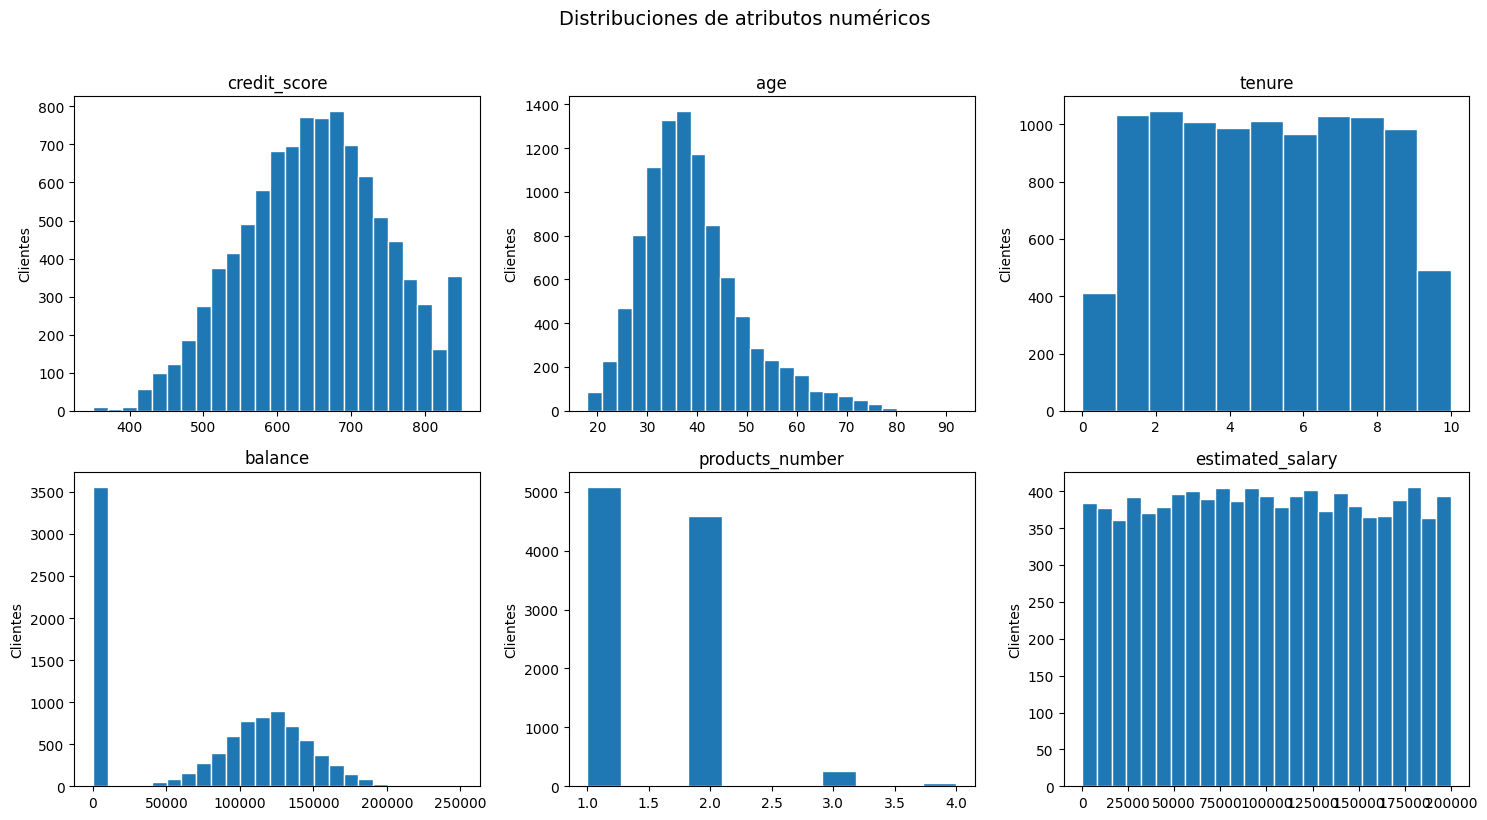

Medianas por estado de abandono:


,age,credit_score,tenure,balance,estimated_salary
churn,,,,,
0,36.0,654.0,5.0,91835.16,99654.13
1,45.0,646.0,5.0,109153.96,102127.30


In [10]:
columnas_num = ["credit_score", "age", "tenure", "balance", "products_number", "estimated_salary"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, columnas_num):
    ax.hist(df[col].dropna(), bins=25 if col not in ["tenure", "products_number"] else 11, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Clientes")
plt.suptitle("Distribuciones de atributos numéricos", y=1.02, fontsize=14)
plt.tight_layout();plt.show()

print("Medianas por estado de abandono:")
display(df.groupby("churn")[["age", "credit_score", "tenure", "balance", "estimated_salary"]].median().round(2))

### 1.5. Variables categóricas y relación con el abandono

Para cada grupo, se muestran simultáneamente la tasa de churn y su tamaño. Interpretar una tasa extrema sin conocer cuántos clientes la componen puede llevar a conclusiones engañosas; además, diferencias observadas entre grupos no implican que la categoría sea la causa del abandono.

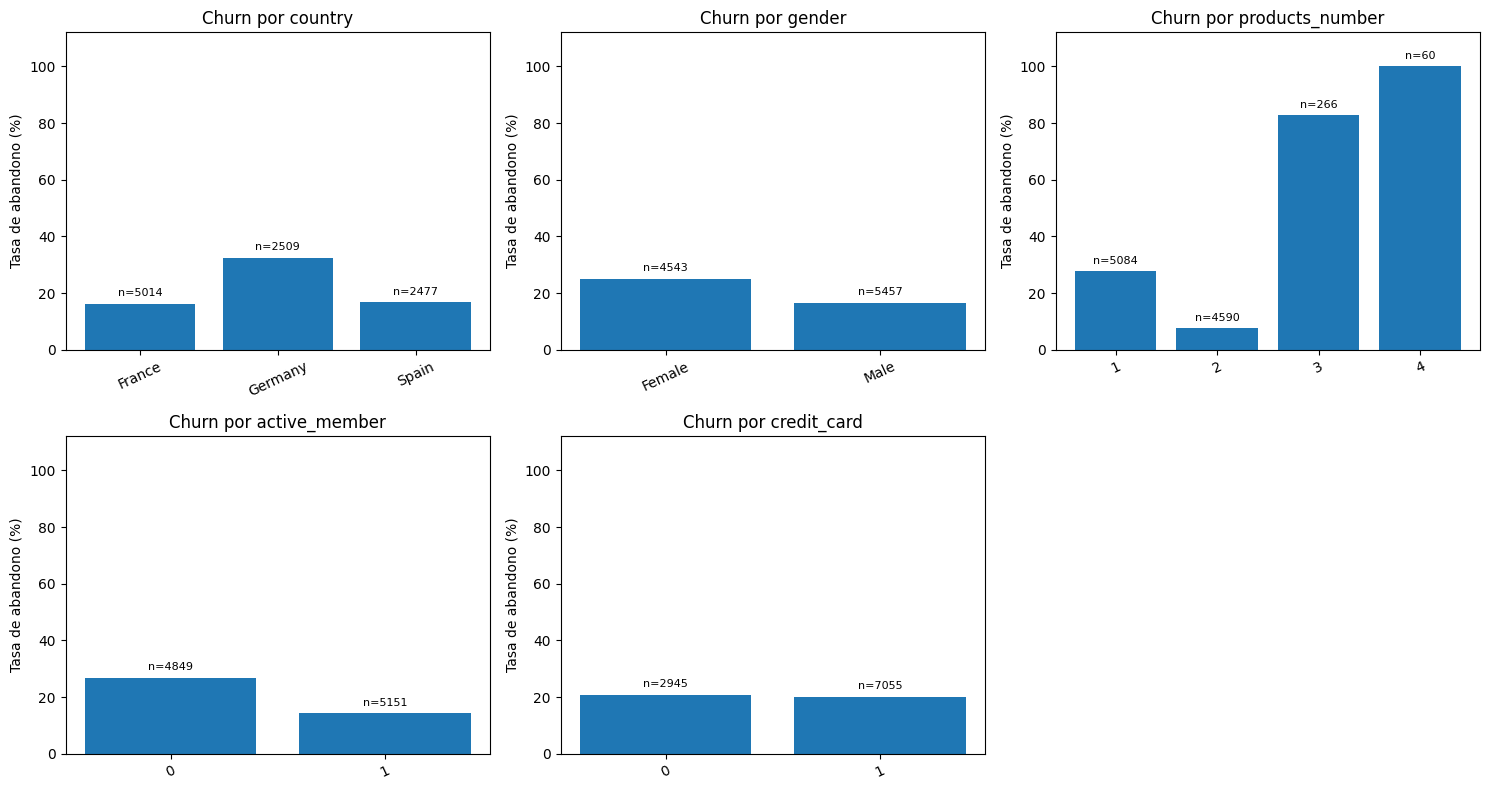

Tasa por country


,clientes,abandonan,churn (%)
country,,,
France,5014,810,16.15
Germany,2509,814,32.44
Spain,2477,413,16.67


Tasa por gender


,clientes,abandonan,churn (%)
gender,,,
Female,4543,1139,25.07
Male,5457,898,16.46


Tasa por products_number


,clientes,abandonan,churn (%)
products_number,,,
1,5084,1409,27.71
2,4590,348,7.58
3,266,220,82.71
4,60,60,100.00


Tasa por active_member


,clientes,abandonan,churn (%)
active_member,,,
0,4849,1302,26.85
1,5151,735,14.27


Tasa por credit_card


,clientes,abandonan,churn (%)
credit_card,,,
0,2945,613,20.81
1,7055,1424,20.18


In [11]:
columnas_grupo = ["country", "gender", "products_number", "active_member", "credit_card"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, columnas_grupo):
    resumen = df.groupby(col, dropna=False)["churn"].agg(n="size", tasa="mean").sort_index()
    bars = ax.bar(resumen.index.astype(str), resumen["tasa"]*100)
    ax.set_title(f"Churn por {col}")
    ax.set_ylabel("Tasa de abandono (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, 112)
    for barra, n in zip(bars, resumen["n"]):
        ax.text(barra.get_x()+barra.get_width()/2, barra.get_height()+2,
                f"n={n}", ha="center", va="bottom", fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout();plt.show()

for col in columnas_grupo:
    print(f"Tasa por {col}")
    tabla = df.groupby(col)["churn"].agg(clientes="size", abandonan="sum", tasa="mean")
    tabla["tasa"] = (100*tabla["tasa"]).round(2)
    display(tabla.rename(columns={"tasa": "churn (%)"}))

### 1.6. Conclusiones descriptivas

Los resultados permiten formular hipótesis descriptivas para la etapa de modelado:

- La clase de abandono es minoritaria (aproximadamente una quinta parte de los clientes), por lo que no debemos seleccionar un modelo exclusivamente por accuracy.
- `age`, `products_number`, `active_member` y `country` presentan diferencias visibles entre grupos, conviene contrastarlas con modelos e interpretabilidad.
- La tasa para clientes con cuatro productos es especialmente alta, pero se basa en un grupo pequeño, por lo que no se debe generalizar sin evaluar incertidumbre.
- El conjunto es europeo. Para aplicar el modelo a Colombia habrá posibles cambios en mercado, clientes y distribución de atributos.
- Las diferencias entre categorías de género u otras características deben tratarse con cuidado y sin interpretarlas como relaciones causales.

### 1.7. División estratificada

Para facilitar una comparación justa de al menos dos modelos, se conservará la misma división estratificada 60 % entrenamiento, 20 % validación y 20 % prueba, con semilla 42, como en las prácticas de clasificación.

**Prevención de fuga de información:** la imputación de numéricas con mediana, el escalamiento `StandardScaler` y la codificación one-hot se definen dentro de un `ColumnTransformer`. Cuando optimicemos hiperparámetros con validación cruzada, ese transformador debe estar dentro del `Pipeline` del modelo, de manera que se ajuste en cada fold solo con sus datos de entrenamiento. La prueba final quedará reservada para la evaluación definitiva.

No balanceamos clases todavía: hacerlo indiscriminadamente alteraría la prevalencia relevante para el negocio. Si en el punto 2 se compara ponderación de clases o remuestreo, deberá aplicarse únicamente en entrenamiento, idealmente dentro de validación cruzada.

In [12]:
# Partición de índices con estratificación para conservar la prevalencia de churn.
X = df.drop(columns=["churn"]).copy()
y = df["churn"].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

tabla_particiones = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Filas": [len(X_train), len(X_val), len(X_test)],
    "Churn (%)": [round(100*s.mean(), 2) for s in [y_train, y_val, y_test]],
})
display(tabla_particiones)

numericas = ["credit_score", "age", "tenure", "balance", "products_number", "estimated_salary"]
binarias = ["credit_card", "active_member"]
categoricas = ["country", "gender"]

preprocessor = ColumnTransformer(transformers=[
    ("numericas", Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
    ]), numericas),
    ("binarias", "passthrough", binarias),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
], remainder="drop")

# Solo comprobación de que la transformación funciona; se reajustará dentro del Pipeline del modelo durante la validación cruzada.
preprocessor_demo = clone(preprocessor)
X_train_demo = preprocessor_demo.fit_transform(X_train)
X_val_demo = preprocessor_demo.transform(X_val)
X_test_demo = preprocessor_demo.transform(X_test)
for nombre, X_t in [("Train", X_train_demo), ("Val", X_val_demo), ("Test", X_test_demo)]:
    X_arr = X_t.toarray() if hasattr(X_t, "toarray") else np.asarray(X_t)
    print(f"{nombre}: {X_arr.shape} | nulos: {np.isnan(X_arr).sum()} | infinitos: {np.isinf(X_arr).sum()}")

,Conjunto,Filas,Churn (%)
0,Entrenamiento,6000,20.37
1,Validación,2000,20.40
2,Prueba,2000,20.35


Train: (6000, 13) | nulos: 0 | infinitos: 0
Val: (2000, 13) | nulos: 0 | infinitos: 0
Test: (2000, 13) | nulos: 0 | infinitos: 0


In [13]:
imputador = (
    preprocessor_demo
    .named_transformers_["numericas"]
    .named_steps["imputacion"]
)

tabla_imputacion = pd.DataFrame({
    "Variable": numericas,
    "Mediana de entrenamiento": imputador.statistics_,
    "Nulos en entrenamiento": X_train[numericas].isna().sum().values
})

display(tabla_imputacion)

,Variable,Mediana de entrenamiento,Nulos en entrenamiento
0,credit_score,652.00,150
1,age,37.00,193
2,tenure,5.00,3
3,balance,96694.39,132
4,products_number,1.00,0
5,estimated_salary,100930.38,208


### 1.8. Cierre del punto 1

**Se documentó:** tamaño y estructura, diccionario de variables, faltantes, duplicados e inconsistencias, distribuciones, tasas de abandono por subgrupos, conjunto depurado y particiones sin solapamiento, transformador reutilizable para el entrenamiento.

**Decisiones a evaluar en el siguiente punto:** comparar por lo menos dos clasificadores, seleccionar por resultados en validación sin consultar prueba, usar métricas apropiadas para la clase positiva e investigar si las características derivadas de la Práctica 2 mejoran el F1 o el beneficio esperado.

**Límites:** no hay identificador único que confirme personas distintas; no conocemos fechas de observación ni la definición operacional exacta de abandono. El origen europeo limita la extrapolación a Colombia.

# Punto 2: Entrenamiento del modelo de Machine Learning

**Objetivo del enunciado:** entrenar al menos dos modelos para predecir `churn`, documentar las divisiones, la estimación de hiperparámetros y la selección del modelo.

**Metodología:**

1. Comparar una regresión logística, un árbol de decisión y un Random Forest, como en la Práctica 2 (Clasificación).
2. Ajustar los hiperparámetros con `GridSearchCV` y validación cruzada estratificada de cinco particiones solo sobre entrenamiento.
3. Mantener `preprocessor` dentro de cada pipeline para que la imputación, la codificación y el escalamiento se ajusten correctamente en cada partición de la validación cruzada.
4. Usar validación (20 %) para comparar los algoritmos y seleccionar el mejor. No consultar el conjunto de prueba (20 %) en este punto.

**Métrica prioritaria:** F1 para `churn = 1`. El abandono es la clase minoritaria y, para el negocio, importan tanto los falsos negativos (clientes en riesgo que no son detectados) como los falsos positivos (clientes contactados innecesariamente). Revisaremos también `precision` y `recall`, pero la decisión económica definitiva se realizará en el punto 5.

### 2.1. Definición de modelos y espacio de hiperparámetros

Los tres clasificadores usan exactamente las mismas variables de entrada, particiones y pasos de preprocesamiento del punto 1.

- **Regresión logística:** como modelo de referencia lineal; se busca la intensidad de regularización `C` y si se compensa el desbalance por ponderación de clases.
- **Árbol de decisión:** permite reglas interpretables; se busca la profundidad máxima, el mínimo de observaciones por hoja y la ponderación de clases para controlar el sobreajuste.
- **Random Forest:** ensamble de árboles que puede capturar interacciones y relaciones no lineales; se busca profundidad, tamaño mínimo de las hojas y ponderación de clases. Se usan 200 árboles en todos los candidatos para mantener comparabilidad y moderar el costo computacional.

`class_weight="balanced"` no remuestrea ni modifica la proporción real de abandono: asigna mayor peso a la clase minoritaria durante el entrenamiento.

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

configuraciones = {
    "Regresión logística": {
        "estimador": LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE),
        "parametros": {
            "clasificador__C": [0.1, 1.0, 10.0],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
    "Árbol de decisión": {
        "estimador": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "parametros": {
            "clasificador__max_depth": [4, 7, 10],
            "clasificador__min_samples_leaf": [10, 30],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
    "Random Forest": {
        "estimador": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
        "parametros": {
            "clasificador__max_depth": [8, None],
            "clasificador__min_samples_leaf": [2, 10],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
}

espacio_busqueda = pd.DataFrame([
    {"Modelo": nombre,
     "Configuraciones": int(np.prod([len(v) for v in config["parametros"].values()])),
     "Parámetros": ", ".join(p.replace("clasificador__", "") for p in config["parametros"])}
    for nombre, config in configuraciones.items()
])
display(espacio_busqueda)

,Modelo,Configuraciones,Parámetros
0,Regresión logística,6,"C, class_weight"
1,Árbol de decisión,12,"max_depth, min_samples_leaf, class_weight"
2,Random Forest,8,"max_depth, min_samples_leaf, class_weight"


### 2.2. Búsqueda de hiperparámetros con validación cruzada

Para cada modelo, `GridSearchCV` entrena todos los candidatos en cinco particiones estratificadas del conjunto de entrenamiento (6.000 clientes). Su criterio de selección es el promedio de F1 para la clase de abandono. El mejor modelo se reajusta automáticamente utilizando los 6.000 registros de entrenamiento (`refit=True`).

Como `preprocessor` está dentro del `Pipeline`, las medianas y los parámetros de escalamiento de cada iteración se calculan únicamente con la parte de entrenamiento correspondiente. Así evitamos fuga de información durante la búsqueda.

In [15]:
busquedas = {}
mejores_modelos = {}
filas_cv = []

for nombre, config in configuraciones.items():
    pipeline = Pipeline([
        ("preprocesamiento", clone(preprocessor)),
        ("clasificador", clone(config["estimador"])),
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=config["parametros"],
        scoring="f1",
        cv=cv,
        refit=True,
        n_jobs=2,
        return_train_score=False,
        error_score="raise",
    )
    busqueda.fit(X_train, y_train)

    busquedas[nombre] = busqueda
    mejores_modelos[nombre] = busqueda.best_estimator_
    idx = busqueda.best_index_
    filas_cv.append({
        "Modelo": nombre,
        "F1_CV_promedio": busqueda.best_score_,
        "F1_CV_desviacion": busqueda.cv_results_["std_test_score"][idx],
        "Mejores_hiperparametros": {k.replace("clasificador__", ""): v
                                    for k, v in busqueda.best_params_.items()},
    })
    print(f"{nombre}: mejor F1 CV = {busqueda.best_score_:.4f} | "
          f"parámetros = {filas_cv[-1]['Mejores_hiperparametros']}")

tabla_cv = pd.DataFrame(filas_cv).sort_values("F1_CV_promedio", ascending=False).reset_index(drop=True)
display(tabla_cv)

Regresión logística: mejor F1 CV = 0.4954 | parámetros = {'C': 1.0, 'class_weight': 'balanced'}
Árbol de decisión: mejor F1 CV = 0.5691 | parámetros = {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 10}
Random Forest: mejor F1 CV = 0.6090 | parámetros = {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 10}


,Modelo,F1_CV_promedio,F1_CV_desviacion,Mejores_hiperparametros
0,Random Forest,0.609042,0.024149,"{'class_weight': 'balanced', 'max_depth': None..."
1,Árbol de decisión,0.569116,0.020302,"{'class_weight': 'balanced', 'max_depth': 7, '..."
2,Regresión logística,0.495436,0.019084,"{'C': 1.0, 'class_weight': 'balanced'}"


### 2.3. Comparación sobre validación

Tras encontrar los mejores hiperparámetros de cada algoritmo, evaluamos sus predicciones sobre los 2.000 clientes de validación, que no participaron en las búsquedas.

Usamos el mismo umbral de 0,5 para que la comparación sea coherente. Para `churn = 1`, la precisión indica qué proporción de los clientes marcados como posibles desertores realmente abandonó. El recall indica qué proporción de los desertores reales fue detectada. F1 resume ambas métricas.

In [16]:
filas_validacion = []

for nombre, modelo in mejores_modelos.items():
    pred_val = modelo.predict(X_val)
    pred_train = modelo.predict(X_train)
    filas_validacion.append({
        "Modelo": nombre,
        "F1_validacion": f1_score(y_val, pred_val),
        "Precision_validacion": precision_score(y_val, pred_val, zero_division=0),
        "Recall_validacion": recall_score(y_val, pred_val, zero_division=0),
        "Exactitud_validacion": accuracy_score(y_val, pred_val),
        "F1_entrenamiento": f1_score(y_train, pred_train),
    })

tabla_validacion = (pd.DataFrame(filas_validacion)
                    .sort_values(["F1_validacion", "Recall_validacion"], ascending=False)
                    .reset_index(drop=True))
tabla_validacion["Brecha_train_val"] = (
    tabla_validacion["F1_entrenamiento"] - tabla_validacion["F1_validacion"]
)
display(tabla_validacion.round(4))

,Modelo,F1_validacion,Precision_validacion,Recall_validacion,Exactitud_validacion,F1_entrenamiento,Brecha_train_val
0,Random Forest,0.6042,0.5724,0.6397,0.829,0.7420,0.1378
1,Árbol de decisión,0.5639,0.4705,0.7034,0.778,0.6144,0.0506
2,Regresión logística,0.4895,0.3804,0.6863,0.708,0.4944,0.0049


### 2.4. Visualización y diagnóstico de sobreajuste

La comparación de F1 de validación cruzada y de validación independiente permite revisar si los resultados son consistentes. También calculamos la brecha entre F1 de entrenamiento y de validación: una brecha positiva muy grande puede indicar sobreajuste.

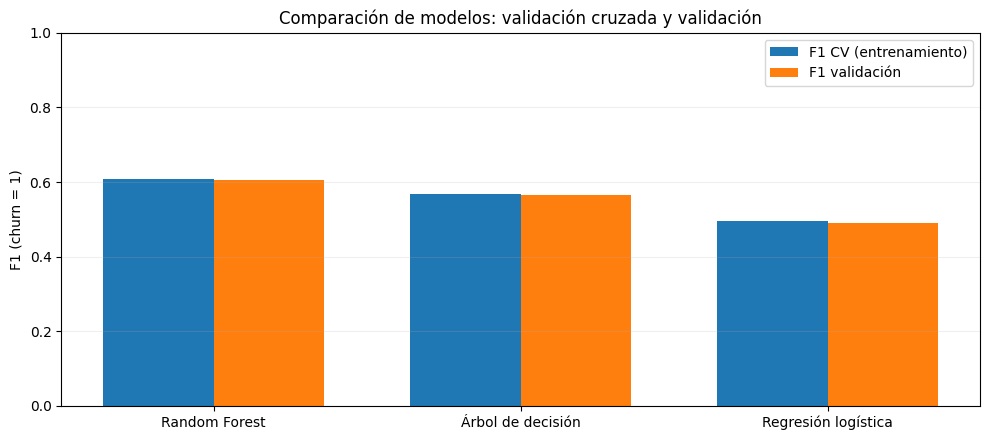

In [17]:
comparacion = tabla_validacion.merge(
    tabla_cv[["Modelo", "F1_CV_promedio"]], on="Modelo", how="left"
)

x_pos = np.arange(len(comparacion))
ancho = 0.36
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x_pos - ancho / 2, comparacion["F1_CV_promedio"], ancho, label="F1 CV (entrenamiento)")
ax.bar(x_pos + ancho / 2, comparacion["F1_validacion"], ancho, label="F1 validación")
ax.set_xticks(x_pos, comparacion["Modelo"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1 (churn = 1)")
ax.set_title("Comparación de modelos: validación cruzada y validación")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 2.5. Selección del modelo para los puntos siguientes

**Regla de selección:** el modelo con mayor F1 de validación, usando 0,5 como umbral.

In [18]:
nombre_modelo_final = tabla_validacion.loc[0, "Modelo"]
modelo_final = mejores_modelos[nombre_modelo_final]
hiperparametros_finales = tabla_cv.set_index("Modelo").loc[
    nombre_modelo_final, "Mejores_hiperparametros"
]

print("Modelo seleccionado:", nombre_modelo_final)
print("Hiperparámetros:", hiperparametros_finales)
print("F1 de validación:", round(float(tabla_validacion.loc[0, "F1_validacion"]), 4))
print("Recall de validación:", round(float(tabla_validacion.loc[0, "Recall_validacion"]), 4))

assert set(mejores_modelos) == set(configuraciones)
assert len(X_train) == 6000 and len(X_val) == 2000 and len(X_test) == 2000

Modelo seleccionado: Random Forest
Hiperparámetros: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 10}
F1 de validación: 0.6042
Recall de validación: 0.6397


### 2.6. Resultados y conclusiones del entrenamiento

En validación, Random Forest fue el mejor modelo con F1 = 0,6042, seguido por árbol de decisión (F1 = 0,5639) y regresión logística (F1 = 0,4895). El resultado de Random Forest es consistente con su promedio de F1 en validación cruzada (0,6090), por lo que la diferencia entre ambos conjuntos es pequeña.

**Comparación desde el problema de negocio:** Random Forest presenta mejor precisión (0,5724) que el árbol de decisión (0,4705), mientras que el árbol presenta mejor recall (0,7034 frente a 0,6397). Esto revela un intercambio relevante: si la empresa prioriza detectar más posibles desertores, el árbol merece consideración, pero contactaría proporcionalmente a más clientes que no abandonan. La decisión económica se examinará con los costos y beneficios del punto 5.

**Hiperparámetros elegidos mediante validación cruzada:**

- Regresión logística: `C=1.0`, `class_weight="balanced"`.
- Árbol de decisión: `max_depth=7`, `min_samples_leaf=10`, `class_weight="balanced"`.
- Random Forest: `n_estimators=200`, `max_depth=None`, `min_samples_leaf=10`, `class_weight="balanced"`.

**Sobreajuste:** Random Forest obtuvo F1 = 0,7420 en entrenamiento y 0,6042 en validación; esta brecha aconseja vigilar el sobreajuste, aunque su resultado en la validación independiente es similar al promedio de la CV. No se deben tratar las diferencias observadas como prueba de superioridad estadística: para eso se utilizarán las técnicas de comparación de la Práctica 4 en el punto 3.

**Selección actual:** `nombre_modelo_final = "Random Forest"` y `modelo_final` contiene el pipeline ya entrenado, incluyendo la preparación y el clasificador. La selección se realizó sin calcular predicciones ni métricas sobre el conjunto de prueba.

**Limitaciones:** los datos proceden de clientes europeos, no se conoce la ventana temporal exacta del abandono y el umbral usado todavía es 0,5. Antes de aplicar el modelo a un banco colombiano se necesitaría validar su desempeño local y ajustar las decisiones al impacto económico de la campaña.

# Punto 3: Análisis cuantitativo de los resultados

**Objetivo:** calcular las métricas de evaluación de los modelos, explicar qué representan en el problema de abandono y justificar la selección del punto 2. Se revisarán los errores, la capacidad de ordenar clientes por riesgo y la incertidumbre de las métricas.

**Metodología:**

- Se usan los tres pipelines ya entrenados en el punto 2. No se buscan hiperparámetros ni se reentrena usando prueba.
- Se evalúa una sola vez el conjunto de prueba estratificado con el umbral original de 0,5.
- La comparación estadística posterior es descriptiva y confirmatoria, no se usa para elegir un modelo nuevo ni para ajustar el umbral con prueba.
- `churn = 1` es la clase positiva. Una predicción positiva produciría un contacto en una campaña hipotética, esto no significa que el cliente acepte la oferta.

Referencia metodológica: Práctica 4 (bootstrapping y comparación de modelos) y las diapositivas de vistas en clase.

### 3.1. Métricas sobre el conjunto de prueba

- **Precisión (VP/(VP+FP))**: de los clientes que el modelo recomienda contactar, qué proporción realmente iba a abandonar. Una precisión alta permite evitar campañas innecesarias.
- **Recall (VP/(VP+FN))**: de los clientes que iban a abandonar, cuántos detectamos. Un valor alto reduce oportunidades de retención perdidas.
- **F1**: media armónica de precisión y recall. Es la métrica de selección utilizada en el punto 2.
- **Accuracy ((VP+VN)/N)**: proporción global de aciertos; se debe comparar con la referencia de predecir siempre la clase mayoritaria.
- **Especificidad (VN/(VN+FP))**: proporción de clientes que permanecen y son correctamente excluidos de la campaña.
- **ROC-AUC**: discriminación entre quienes abandonan y quienes no, sobre todos los umbrales.
- **AP (average precision)** resume precisión-recall con énfasis en la clase positiva.

In [19]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    balanced_accuracy_score,
)

# Mantener la selección del punto 2 sin recalibrar ni reentrenar modelos.
predicciones_test = {}
probabilidades_test = {}
matrices_test = {}
filas_test = []

for nombre, modelo in mejores_modelos.items():
    pred = np.asarray(modelo.predict(X_test))
    prob = np.asarray(modelo.predict_proba(X_test)[:, 1])
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    predicciones_test[nombre] = pred
    probabilidades_test[nombre] = prob
    matrices_test[nombre] = (tn, fp, fn, tp)

    filas_test.append({
        "Modelo": nombre,
        "F1": f1_score(y_test, pred, zero_division=0),
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Exactitud": accuracy_score(y_test, pred),
        "Especificidad": tn / (tn + fp),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "AP (PR)": average_precision_score(y_test, prob),
        "Contactados": int(tp + fp),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    })

tabla_test = (pd.DataFrame(filas_test)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True))

baseline_mayoritaria = float((y_test == 0).mean())
print(f"Clientes en prueba: {len(y_test):,} | churn: {y_test.mean():.2%}")
print(f"Exactitud de predecir siempre NO churn: {baseline_mayoritaria:.4f} (F1 para churn = 0)")
display(tabla_test.round(4))


Clientes en prueba: 2,000 | churn: 20.35%
Exactitud de predecir siempre NO churn: 0.7965 (F1 para churn = 0)


,Modelo,F1,Precisión,Recall,Exactitud,Especificidad,Balanced accuracy,ROC-AUC,AP (PR),Contactados,VP,FP,FN,VN
0,Random Forest,0.6180,0.5766,0.6658,0.8325,0.8751,0.7705,0.8605,0.6917,470,271,199,136,1394
1,Árbol de decisión,0.5556,0.4604,0.7002,0.7720,0.7903,0.7453,0.8339,0.6534,619,285,334,122,1259
2,Regresión logística,0.4926,0.3828,0.6904,0.7105,0.7156,0.7030,0.7630,0.4491,734,281,453,126,1140


### 3.2. Matrices de confusión y tipos de error

En cada matriz las filas son las clases reales y las columnas son las predicciones:

| | Predice permanencia (0) | Predice abandono (1) |
|---|---|---|
| Permanece (0) | Verdaderos negativos (VN) | Falsos positivos (FP): campaña innecesaria |
| Abandona (1) | Falsos negativos (FN): oportunidad perdida | Verdaderos positivos (VP): campaña focalizada |

La empresa debe prestar atención a FP y FN, ambos representan costos o beneficios potencialmente perdidos.

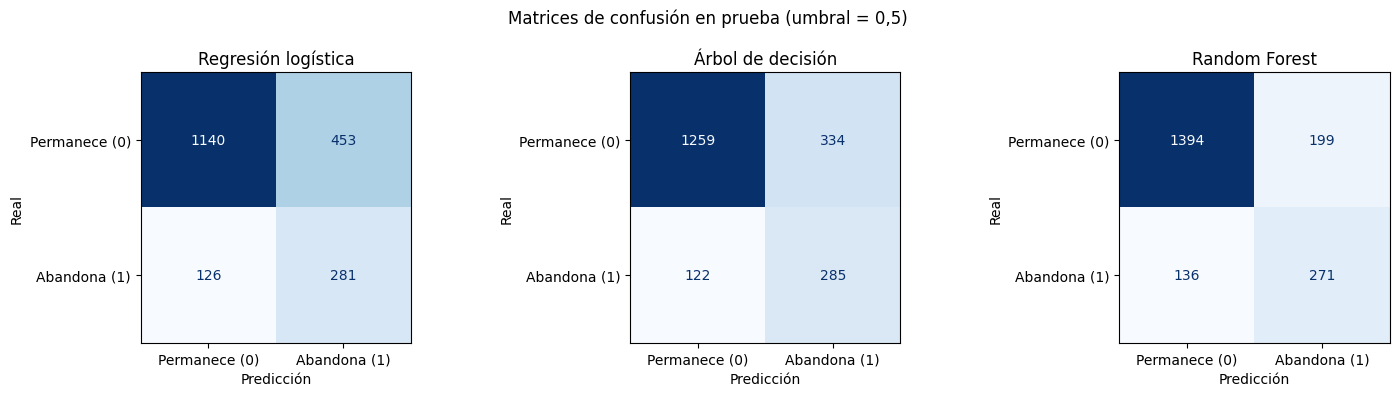

,Modelo,Contactados,VP,FP,FN,VN,Contactados (%)
0,Random Forest,470,271,199,136,1394,23.50
1,Árbol de decisión,619,285,334,122,1259,30.95
2,Regresión logística,734,281,453,126,1140,36.70


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, mejores_modelos):
    cm = confusion_matrix(y_test, predicciones_test[nombre], labels=[0, 1])
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Permanece (0)", "Abandona (1)"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.suptitle("Matrices de confusión en prueba (umbral = 0,5)")
plt.tight_layout()
plt.show()

resumen_contacto = tabla_test[["Modelo", "Contactados", "VP", "FP", "FN", "VN"]].copy()
resumen_contacto["Contactados (%)"] = (100 * resumen_contacto["Contactados"] / len(y_test)).round(2)
display(resumen_contacto)


### 3.3. Curvas ROC y precisión-recall

Las curvas permiten comparar los algoritmos sin imponer un único umbral. La línea diagonal en ROC representa discriminación aleatoria. En la gráfica precisión-recall, la línea horizontal de referencia corresponde a la prevalencia de abandono en prueba.

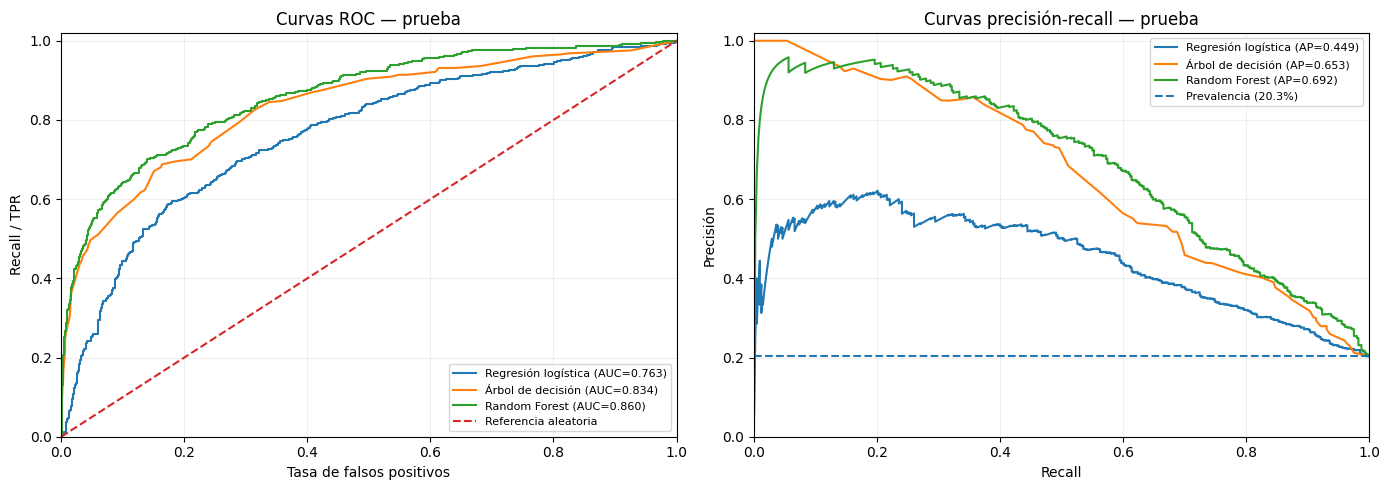

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, proba in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, proba):.3f})")
    axes[1].plot(rec, prec, label=f"{nombre} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", label="Referencia aleatoria")
axes[1].axhline(float(y_test.mean()), linestyle="--", label=f"Prevalencia ({y_test.mean():.1%})")
axes[0].set(title="Curvas ROC — prueba", xlabel="Tasa de falsos positivos", ylabel="Recall / TPR", xlim=(0, 1), ylim=(0, 1.02))
axes[1].set(title="Curvas precisión-recall — prueba", xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 3.4. Incertidumbre: bootstrap de las métricas

Con el enfoque visto en la Práctica 4, tomamos 1.000 muestras de clientes con reemplazo del conjunto de prueba. Los clasificadores permanecen fijos, no hay que reentrenarlos en cada réplica. En cada muestra se calcula F1, precisión y recall; el intervalo del 95 % utiliza los percentiles 2,5 y 97,5.

Para comparar modelos sobre los mismos clientes hacemos un bootstrap pareado: cada réplica usa exactamente los mismos índices para Random Forest y para su comparador. Calculamos la distribución de `F1_RF − F1_otro`, su intervalo y un valor p empírico. Esta comparación no sirve para ajustar nuevamente los modelos sobre prueba.

Un intervalo que incluye 0 no permite afirmar una diferencia estadísticamente clara en F1. Incluso si excluye 0, todavía debe evaluarse si la diferencia es importante económicamente para el banco.

In [22]:
B = 1000
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = np.asarray(y_test, dtype=int)
N_test = len(y_test_arr)
indices_bootstrap = rng.integers(0, N_test, size=(B, N_test))

# Calcular los conteos con NumPy por lotes: mismo bootstrap, sin repetir llamadas costosas a las funciones de scikit-learn para cada réplica.
y_b = y_test_arr[indices_bootstrap]
metricas_bootstrap = ["F1", "Precisión", "Recall"]
distribuciones_bootstrap = {}

for nombre, pred in predicciones_test.items():
    p_b = np.asarray(pred, dtype=int)[indices_bootstrap]
    vp = np.count_nonzero((y_b == 1) & (p_b == 1), axis=1)
    fp = np.count_nonzero((y_b == 0) & (p_b == 1), axis=1)
    fn = np.count_nonzero((y_b == 1) & (p_b == 0), axis=1)

    distribuciones_bootstrap[nombre] = {
        "F1": np.divide(2 * vp, 2 * vp + fp + fn, out=np.zeros(B), where=(2 * vp + fp + fn) != 0),
        "Precisión": np.divide(vp, vp + fp, out=np.zeros(B), where=(vp + fp) != 0),
        "Recall": np.divide(vp, vp + fn, out=np.zeros(B), where=(vp + fn) != 0),
    }

filas_ic = []
for nombre, dist in distribuciones_bootstrap.items():
    for met in metricas_bootstrap:
        li, ls = np.percentile(dist[met], [2.5, 97.5])
        filas_ic.append({
            "Modelo": nombre,
            "Métrica": met,
            "Observado": float(tabla_test.set_index("Modelo").loc[nombre, met]),
            "IC 95 % inferior": li,
            "IC 95 % superior": ls,
            "Amplitud IC": ls - li,
        })

tabla_ic = pd.DataFrame(filas_ic)
display(tabla_ic.round(4))


,Modelo,Métrica,Observado,IC 95 % inferior,IC 95 % superior,Amplitud IC
0,Regresión logística,F1,0.4926,0.4550,0.5229,0.0680
1,Regresión logística,Precisión,0.3828,0.3459,0.4134,0.0675
2,Regresión logística,Recall,0.6904,0.6423,0.7337,0.0914
3,Árbol de decisión,F1,0.5556,0.5186,0.5872,0.0685
4,Árbol de decisión,Precisión,0.4604,0.4195,0.4951,0.0756
5,Árbol de decisión,Recall,0.7002,0.6559,0.7460,0.0901
6,Random Forest,F1,0.6180,0.5763,0.6535,0.0772
7,Random Forest,Precisión,0.5766,0.5282,0.6176,0.0894
8,Random Forest,Recall,0.6658,0.6215,0.7115,0.0900


,Comparación,Diferencia F1 observada,IC 95 % inferior,IC 95 % superior,p bootstrap aproximado,IC excluye cero
0,Random Forest − Regresión logística,0.1255,0.0946,0.1561,0.002,True
1,Random Forest − Árbol de decisión,0.0625,0.0318,0.0931,0.002,True


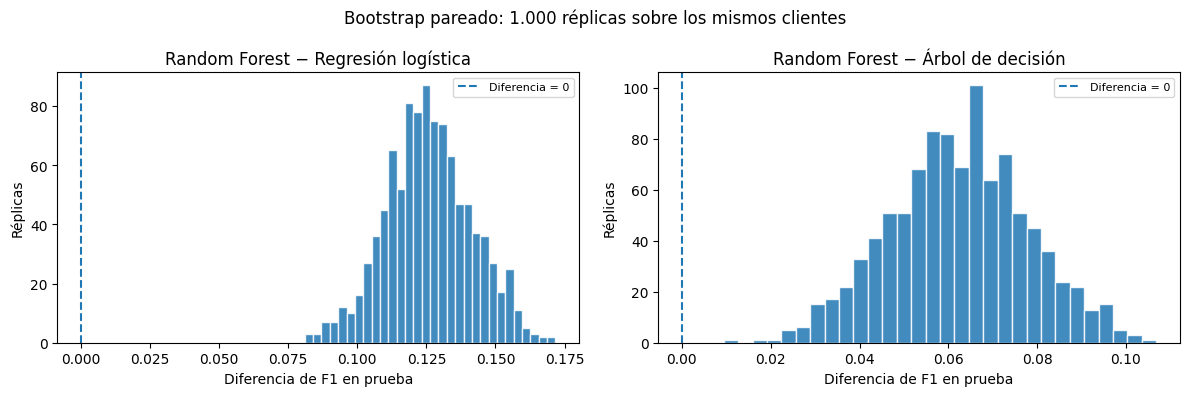

In [23]:
# Comparaciones pareadas de F1 frente al modelo seleccionado, con la misma muestra de clientes.
filas_diferencias = []
diferencias_bootstrap = {}
for otro in [nombre for nombre in mejores_modelos if nombre != nombre_modelo_final]:
    dif = (distribuciones_bootstrap[nombre_modelo_final]["F1"]
           - distribuciones_bootstrap[otro]["F1"])
    diferencias_bootstrap[otro] = dif
    li, ls = np.percentile(dif, [2.5, 97.5])
    f1_rf = tabla_test.set_index("Modelo").loc[nombre_modelo_final, "F1"]
    f1_otro = tabla_test.set_index("Modelo").loc[otro, "F1"]
    # p aproximado bilateral basado en las réplicas: 2*min(fracción <=0, fracción >=0)
    p_aprox = min(1., 2 * (min(np.count_nonzero(dif <= 0), np.count_nonzero(dif >= 0)) + 1) / (B + 1))
    filas_diferencias.append({
        "Comparación": f"{nombre_modelo_final} − {otro}",
        "Diferencia F1 observada": f1_rf - f1_otro,
        "IC 95 % inferior": li,
        "IC 95 % superior": ls,
        "p bootstrap aproximado": p_aprox,
        "IC excluye cero": bool(li > 0 or ls < 0),
    })

tabla_diferencias = pd.DataFrame(filas_diferencias)
display(tabla_diferencias.round(4))

fig, axes = plt.subplots(1, len(diferencias_bootstrap), figsize=(12, 4))
for ax, (otro, dif) in zip(np.atleast_1d(axes), diferencias_bootstrap.items()):
    ax.hist(dif, bins=30, edgecolor="white", alpha=0.85)
    ax.axvline(0, linestyle="--", label="Diferencia = 0")
    ax.set(title=f"Random Forest − {otro}", xlabel="Diferencia de F1 en prueba", ylabel="Réplicas")
    ax.legend(fontsize=8)
plt.suptitle("Bootstrap pareado: 1.000 réplicas sobre los mismos clientes")
plt.tight_layout()
plt.show()


### 3.5. ¿Qué decisiones de entrenamiento pudieron ayudar? ¿Qué debemos mejorar?

Para identificar indicios del efecto de la ponderación de clases, revisamos los resultados de validación cruzada producidos en el punto 2: el mejor F1 disponible entre configuraciones con `class_weight=None` y con `class_weight="balanced"` para cada algoritmo. Este análisis no utiliza prueba ni constituye una comparación causal controlada.

Como oportunidades de mejora, podríamos ajustar el umbral de clasificación usando el conjunto de validación, buscando un mejor equilibrio entre precisión y recall. También sería útil evaluar nuevas características, como las relacionadas con el saldo y la cantidad de productos, e intentar reducir el sobreajuste observado en Random Forest. Finalmente, antes de implementar el modelo en Colombia, sería necesario validarlo con datos de clientes locales.

In [24]:
filas_ponderacion = []
for nombre, busqueda in busquedas.items():
    cv_resultados = pd.DataFrame(busqueda.cv_results_)
    for valor_peso in [None, "balanced"]:
        candidatos = cv_resultados[
            cv_resultados["param_clasificador__class_weight"].apply(lambda v: v == valor_peso)
        ]
        filas_ponderacion.append({
            "Modelo": nombre,
            "Ponderación": "Sin ponderación" if valor_peso is None else "Balanceada",
            "Mejor F1 CV del grupo": candidatos["mean_test_score"].max(),
        })

tabla_ponderacion = pd.DataFrame(filas_ponderacion)
display(tabla_ponderacion.pivot(index="Modelo", columns="Ponderación", values="Mejor F1 CV del grupo").round(4))

# Comparación prueba-validación sin alterar la elección original.
tabla_generalizacion = (tabla_validacion[["Modelo", "F1_validacion", "Precision_validacion", "Recall_validacion"]]
                         .merge(tabla_test[["Modelo", "F1", "Precisión", "Recall"]], on="Modelo"))
tabla_generalizacion["Cambio F1 (test - val)"] = tabla_generalizacion["F1"] - tabla_generalizacion["F1_validacion"]
display(tabla_generalizacion.round(4))


Ponderación,Balanceada,Sin ponderación
Modelo,,
Random Forest,0.6090,0.5685
Regresión logística,0.4954,0.3025
Árbol de decisión,0.5691,0.5533


,Modelo,F1_validacion,Precision_validacion,Recall_validacion,F1,Precisión,Recall,Cambio F1 (test - val)
0,Random Forest,0.6042,0.5724,0.6397,0.6180,0.5766,0.6658,0.0138
1,Árbol de decisión,0.5639,0.4705,0.7034,0.5556,0.4604,0.7002,-0.0083
2,Regresión logística,0.4895,0.3804,0.6863,0.4926,0.3828,0.6904,0.0030


### 3.6. Conclusiones del análisis cuantitativo

**1. Modelo elegido y generalización.** Se mantiene Random Forest, seleccionado previamente con validación. En prueba logra F1 = 0,6180, precisión = 0,5766, recall = 0,6658, exactitud = 0,8325, ROC-AUC = 0,8605 y AP = 0,6917. El F1 de validación era 0,6042: la diferencia es pequeña y no indica una pérdida de rendimiento importante entre ambos conjuntos. La exactitud del RF supera el baseline de predecir siempre la clase mayoritaria (0,7965), pero la comparación por F1 es más informativa para los clientes que abandonan.

**2. Errores relevantes para el banco.** De los 407 clientes que abandonaron en prueba, el RF identifica 271 y omite 136. Si se contacta a todos los clasificados como posibles desertores, habría 470 contactos, de los cuales 199 serían innecesarios por corresponder a quienes no iban a abandonar. El árbol detecta 285 desertores (14 adicionales), pero produce 334 falsos positivos (135 adicionales). Por eso no conviene decidir únicamente con recall.

**3. Curvas ROC y precisión-recall.** Las curvas ROC confirman que Random Forest tiene la mayor capacidad de discriminación (AUC = 0,8605), seguido del árbol (0,8339) y la regresión logística (0,7630). Las curvas precisión-recall también favorecen al RF (AP = 0,6917), que mantiene un mejor equilibrio entre detectar desertores y evitar falsos positivos. Esta comparación es especialmente relevante por el desbalance de clases (20,3 % de abandono), ya que permite evaluar el comportamiento de los modelos con distintos umbrales de clasificación.

**4. Incertidumbre y comparación.** Con 1.000 muestras bootstrap, el IC del 95 % del F1 de Random Forest es aproximadamente [0,5763, 0,6535]. El bootstrap pareado compara los tres algoritmos sobre las mismas personas, el F1 del RF supera al del árbol por 0,0625, con IC 95 % de [0,0318, 0,0931], y al de regresión logística por 0,1255, con IC 95 % de [0,0946, 0,1561]. Ambos intervalos excluyen cero. Se trata de evidencia a favor del RF en esta muestra y este protocolo, no de garantía de superioridad en cualquier población.

**5. Decisiones que probablemente favorecieron las métricas.** En la búsqueda de hiperparámetros, la mejor configuración de Random Forest con `class_weight="balanced"` alcanzó F1 CV = 0,6090, frente a 0,5685 de la mejor sin ponderación. Para el árbol, los correspondientes valores fueron 0,5691 y 0,5533. Son comparaciones observacionales entre configuraciones de la búsqueda, no una prueba aislada del efecto de la ponderación. La capacidad de los árboles y ensambles para captar relaciones no lineales es una explicación plausible de su ventaja frente a regresión logística, pero no constituye una prueba de causalidad sobre la mejora.

**Conclusión:** Random Forest ofrece el mejor equilibrio predictivo de los tres modelos con umbral 0,5. Lo conservamos como modelo principal para interpretabilidad y generación de valor, sin asumir todavía que sea el de mayor rentabilidad.